In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


Saving artistainfo.json to artistainfo.json


In [2]:
df = pd.read_json(DATA_RAW / "artistainfo.json")
df


,blues.00000.wav,blues.00001.wav,blues.00002.wav,blues.00003.wav,blues.00004.wav,blues.00005.wav,blues.00006.wav,blues.00007.wav,blues.00008.wav,blues.00009.wav,...,rock.00090.wav,rock.00091.wav,rock.00092.wav,rock.00093.wav,rock.00094.wav,rock.00095.wav,rock.00096.wav,rock.00097.wav,rock.00098.wav,rock.00099.wav
artistas,[Stevie Ray Vaughan],"[Sonny Boy Williamson, Buddy Guy]","[Muddy Waters, Bessie Smith]",[Freddie King],"[Memphis Minnie, Bonnie Raitt]","[Magic Sam, Susan Tedeschi]","[Howlin' Wolf, Robert Johnson]",[Elmore James],[Little Walter],[Memphis Minnie],...,[AC/DC],[Eric Clapton],[The Doors],"[Eric Clapton, Oasis]","[The Rolling Stones, Deep Purple]",[Pearl Jam],[The Clash],[Fleetwood Mac],[Chuck Berry],[Metallica]
discografica,Sun Records,Epic Records,Merge Records,Republic Records,Jive Records,Polydor Records,Arista Records,Tommy Boy Entertainment,XL Recordings,Atlantic Records,...,Sub Pop Records,Interscope Records,Merge Records,Polydor Records,Sire Records,Stax Records,Sun Records,XL Recordings,Motown,Def Jam Recordings
coste,744.006861,4178.851293,3226.400608,3618.766076,1990.810773,909.809896,2311.436986,2794.915781,2844.917684,3760.170756,...,3150.120922,4001.923606,5065.698141,4290.936374,4285.385338,3185.879761,-503.650862,2170.05288,1425.792985,4376.34738


#Tratamiento de los datos JSON

In [3]:
df = df.T
df


,artistas,discografica,coste
blues.00000.wav,[Stevie Ray Vaughan],Sun Records,744.006861
blues.00001.wav,"[Sonny Boy Williamson, Buddy Guy]",Epic Records,4178.851293
blues.00002.wav,"[Muddy Waters, Bessie Smith]",Merge Records,3226.400608
blues.00003.wav,[Freddie King],Republic Records,3618.766076
blues.00004.wav,"[Memphis Minnie, Bonnie Raitt]",Jive Records,1990.810773
...,...,...,...
rock.00095.wav,[Pearl Jam],Stax Records,3185.879761
rock.00096.wav,[The Clash],Sun Records,-503.650862
rock.00097.wav,[Fleetwood Mac],XL Recordings,2170.05288
rock.00098.wav,[Chuck Berry],Motown,1425.792985


In [26]:
df = df.reset_index().rename(columns={'index': 'cancion'})
df.head(5)

,cancion,artistas,discografica,coste
0,blues.00000.wav,[Stevie Ray Vaughan],Sun Records,744.006861
1,blues.00001.wav,"[Sonny Boy Williamson, Buddy Guy]",Epic Records,4178.851293
2,blues.00002.wav,"[Muddy Waters, Bessie Smith]",Merge Records,3226.400608
3,blues.00003.wav,[Freddie King],Republic Records,3618.766076
4,blues.00004.wav,"[Memphis Minnie, Bonnie Raitt]",Jive Records,1990.810773


In [27]:
#En la columna "artistas" tenemos listas de artistas, lo solucionamos con .explode
df_final_artistas=df.explode("artistas")
df_final_artistas

,cancion,artistas,discografica,coste
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.006861
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.851293
1,blues.00001.wav,Buddy Guy,Epic Records,4178.851293
2,blues.00002.wav,Muddy Waters,Merge Records,3226.400608
2,blues.00002.wav,Bessie Smith,Merge Records,3226.400608
...,...,...,...,...
995,rock.00095.wav,Pearl Jam,Stax Records,3185.879761
996,rock.00096.wav,The Clash,Sun Records,-503.650862
997,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05288
998,rock.00098.wav,Chuck Berry,Motown,1425.792985


#Primer análisis general de los datos


In [28]:
#Comprobamos tipo de dato y si existen nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   cancion       1000 non-null   object
 1   artistas      1000 non-null   object
 2   discografica  1000 non-null   object
 3   coste         1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB


In [29]:
df_final_artistas.head()

,cancion,artistas,discografica,coste
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.006861
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.851293
1,blues.00001.wav,Buddy Guy,Epic Records,4178.851293
2,blues.00002.wav,Muddy Waters,Merge Records,3226.400608
2,blues.00002.wav,Bessie Smith,Merge Records,3226.400608


In [30]:
df_final_artistas.tail()

,cancion,artistas,discografica,coste
995,rock.00095.wav,Pearl Jam,Stax Records,3185.879761
996,rock.00096.wav,The Clash,Sun Records,-503.650862
997,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05288
998,rock.00098.wav,Chuck Berry,Motown,1425.792985
999,rock.00099.wav,Metallica,Def Jam Recordings,4376.34738


In [31]:
df_final_artistas.sample(5)

,cancion,artistas,discografica,coste
492,hiphop.00092.wav,Logic,Columbia Records,3779.432191
464,hiphop.00064.wav,Megan Thee Stallion,4AD,1649.34913
907,rock.00007.wav,Pearl Jam,Atlantic Records,3169.252836
776,pop.00076.wav,Lady Gaga,Capitol Records,2577.689133
438,hiphop.00038.wav,J. Cole,Verve Records,4548.953653


In [32]:
#Confirmamos con un segundo método que no hay nulos
df_final_artistas.isnull().sum()

,0
cancion,0
artistas,0
discografica,0
coste,0


In [33]:
#Convertimos la columna coste en un tipo de dato numérico
df_final_artistas["coste"] = pd.to_numeric(df_final_artistas["coste"], errors="coerce").round(2)
df_final_artistas

,cancion,artistas,discografica,coste
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85
1,blues.00001.wav,Buddy Guy,Epic Records,4178.85
2,blues.00002.wav,Muddy Waters,Merge Records,3226.40
2,blues.00002.wav,Bessie Smith,Merge Records,3226.40
...,...,...,...,...
995,rock.00095.wav,Pearl Jam,Stax Records,3185.88
996,rock.00096.wav,The Clash,Sun Records,-503.65
997,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05
998,rock.00098.wav,Chuck Berry,Motown,1425.79


In [34]:
#Confirmamos que la columna coste ahora es de tipo numérico
df_final_artistas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1371 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cancion       1371 non-null   object 
 1   artistas      1371 non-null   object 
 2   discografica  1371 non-null   object 
 3   coste         1371 non-null   float64
dtypes: float64(1), object(3)
memory usage: 85.8+ KB


In [35]:
#Buscamos duplicados en la columna artistas
df_final_artistas["artistas"].duplicated().any()

np.True_

In [36]:
#Vemos si nos merece la pena sacar un id_artista aparte
df_final_artistas["artistas"].value_counts().reset_index()

,artistas,count
0,Eric Clapton,14
1,J. Cole,11
2,Nicki Minaj,11
3,Sharon den Adel,10
4,Loretta Lynn,10
...,...,...
321,Robert Schumann,1
322,Antonio Vivaldi,1
323,T-Bone Walker,1
324,Toots Hibbert,1


In [37]:
total_artistas = df_final_artistas["artistas"].nunique()

print(f"El número total de artistas es: {total_artistas}")

El número total de artistas es: 326


In [38]:
# Comprobación por otro medio que es cierto que hay 326 artistas diferentes
df_final_artistas.to_excel(DATA_PROCESSED / "archivo.xlsx", index=False)


In [39]:
#Añadimos una columna id_artistas para el procesamiento posterior en sql
artistas_unicos = df_final_artistas[["artistas"]].drop_duplicates().reset_index(drop=True)
artistas_unicos["id_artista"] = range(1, len(artistas_unicos) + 1)
df_final_artistas_2 = df_final_artistas.merge(artistas_unicos,on="artistas",how="left")
df_final_artistas_2

,cancion,artistas,discografica,coste,id_artista
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01,1
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85,2
2,blues.00001.wav,Buddy Guy,Epic Records,4178.85,3
3,blues.00002.wav,Muddy Waters,Merge Records,3226.40,4
4,blues.00002.wav,Bessie Smith,Merge Records,3226.40,5
...,...,...,...,...,...
1366,rock.00095.wav,Pearl Jam,Stax Records,3185.88,306
1367,rock.00096.wav,The Clash,Sun Records,-503.65,321
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297
1369,rock.00098.wav,Chuck Berry,Motown,1425.79,301


In [40]:
#Buscamos duplicados en la columna discografica
df_final_artistas["discografica"].duplicated().any()

np.True_

In [41]:
#Vemos si nos merece la pena sacar un id_discografica a parte
df_final_artistas["discografica"].value_counts().reset_index()


,discografica,count
0,Merge Records,104
1,4AD,59
2,Interscope Records,56
3,XL Recordings,53
4,Polydor Records,51
5,EMI Group,51
6,RCA Records,50
7,Sun Records,49
8,Atlantic Records,47
9,Wind-Up Records,46


In [42]:
total_discograficas = df_final_artistas["discografica"].nunique()

print(f"El número total de discograficas es: {total_discograficas}")

El número total de discograficas es: 32


In [43]:
#Añado una columna id_discografica para el procesamiento posterior en sql
discografica_unicos = df_final_artistas_2[["discografica"]].drop_duplicates().reset_index(drop=True)
discografica_unicos["id_discografica"] = range(1, len(discografica_unicos) + 1)
df_final_artistas_3 = df_final_artistas_2.merge(discografica_unicos,on="discografica",how="left")
df_final_artistas_3

,cancion,artistas,discografica,coste,id_artista,id_discografica
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01,1,1
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85,2,2
2,blues.00001.wav,Buddy Guy,Epic Records,4178.85,3,2
3,blues.00002.wav,Muddy Waters,Merge Records,3226.40,4,3
4,blues.00002.wav,Bessie Smith,Merge Records,3226.40,5,3
...,...,...,...,...,...,...
1366,rock.00095.wav,Pearl Jam,Stax Records,3185.88,306,25
1367,rock.00096.wav,The Clash,Sun Records,-503.65,321,1
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297,9
1369,rock.00098.wav,Chuck Berry,Motown,1425.79,301,20


In [44]:
#Creamos la columna género para posteriores cálculos
df_final_artistas_3["genero"] = df_final_artistas_3["cancion"].str.extract(r"([a-zA-Z]+)")
df_final_artistas_3

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01,1,1,blues
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85,2,2,blues
2,blues.00001.wav,Buddy Guy,Epic Records,4178.85,3,2,blues
3,blues.00002.wav,Muddy Waters,Merge Records,3226.40,4,3,blues
4,blues.00002.wav,Bessie Smith,Merge Records,3226.40,5,3,blues
...,...,...,...,...,...,...,...
1366,rock.00095.wav,Pearl Jam,Stax Records,3185.88,306,25,rock
1367,rock.00096.wav,The Clash,Sun Records,-503.65,321,1,rock
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297,9,rock
1369,rock.00098.wav,Chuck Berry,Motown,1425.79,301,20,rock


#Identificación de errores en la columna "coste":

In [45]:
#Creamos otro dataframe que solo tenga en cuenta una fila por cancion y así los costes no se dupliquen
df_unicos = df_final_artistas_3.drop_duplicates(subset='cancion')

In [46]:
#Confirmamos que no hay duplicados
df_unicos[df_unicos.duplicated(subset='cancion')]

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero


In [47]:
#Confirmamos que existen valores negativos, lo que no tendría sentido si hablamos de un pago por derechos de autor
(df_unicos["coste"] < 0).any()

np.True_

##Análisis de los costes negativos

In [48]:
#Ánálisis de las cifras negativas

negativos = df_unicos[(df_unicos['coste'] < 0)]

print(f"Cantidad de negativos: {len(negativos)}")
print(f"Cantidad de negativos: {round(len(negativos)/len(df_unicos['coste'])*100,2)}%")
display(negativos)

#Se plantea la posibilidad de que estas cifras podrían tener sentido si fueran positivas


Cantidad de negativos: 26
Cantidad de negativos: 2.6%


,cancion,artistas,discografica,coste,id_artista,id_discografica,genero
90,blues.00061.wav,Blind Willie Johnson,4AD,-75.24,19,22,blues
99,blues.00068.wav,R.L. Burnside,XL Recordings,-162.14,18,9,blues
119,blues.00082.wav,Buddy Guy,Republic Records,-315.93,3,4,blues
257,classical.00093.wav,Bedřich Smetana,Sire Records,-590.15,56,15,classical
260,classical.00095.wav,George Frideric Handel,Merge Records,-946.54,65,3,classical
312,country.00039.wav,Dolly Parton,Def Jam Recordings,-70.79,89,16,country
341,country.00060.wav,Martina McBride,Elektra Records,-884.22,73,18,country
383,country.00092.wav,Tim McGraw,Tommy Boy Entertainment,-618.03,96,8,country
467,disco.00057.wav,Shalamar,Merge Records,-169.82,127,3,disco
478,disco.00066.wav,Odyssey,Warner Music Group,-561.33,100,14,disco


In [50]:
#Comprobamos si se refieren a una misma discografica/cancion/artista
negativos_group = negativos.groupby(["discografica","artistas", "cancion"]).size().reset_index(name="conteo")
negativos_group

display(negativos_group.sort_values(by="conteo", ascending=False))

,discografica,artistas,cancion,conteo
0,4AD,Blind Willie Johnson,blues.00061.wav,1
1,Arista Records,Khalid,pop.00067.wav,1
2,BMG Rights Management,Ahmad Jamal,jazz.00011.wav,1
3,Def Jam Recordings,Adele,pop.00020.wav,1
4,Def Jam Recordings,Dolly Parton,country.00039.wav,1
5,EMI Group,Nirvana,rock.00027.wav,1
6,Elektra Records,Martina McBride,country.00060.wav,1
7,Interscope Records,The Eagles,rock.00054.wav,1
8,Merge Records,Beyoncé,hiphop.00007.wav,1
9,Merge Records,Drake,pop.00040.wav,1


In [51]:
#Comprobamos si se refieren solo a una misma discografica
negativos_group_discografica = negativos.groupby(["discografica"]).size().reset_index(name="conteo")

display(negativos_group_discografica.sort_values(by="conteo", ascending=False))

,discografica,conteo
7,Merge Records,4
8,Polydor Records,3
13,Tommy Boy Entertainment,2
3,Def Jam Recordings,2
10,Sire Records,2
15,Warner Music Group,2
0,4AD,1
4,EMI Group,1
1,Arista Records,1
5,Elektra Records,1


In [52]:
#Comprobamos el porcentaje de negativos que tiene cada discografica
porcentajes_neg_discog = (df_unicos.groupby("discografica").agg(total=("coste", "size"),negativos=("coste", lambda x: (x < 0).sum()) ))

porcentajes_neg_discog["porcentaje_negativos"] = (porcentajes_neg_discog["negativos"] / porcentajes_neg_discog["total"] * 100).round(2)

display(porcentajes_neg_discog.sort_values("porcentaje_negativos", ascending=False))


,total,negativos,porcentaje_negativos
discografica,,,
Polydor Records,35,3,8.57
Def Jam Recordings,25,2,8.00
Sire Records,26,2,7.69
Warner Music Group,27,2,7.41
Tommy Boy Entertainment,30,2,6.67
Merge Records,80,4,5.00
Verve Records,24,1,4.17
BMG Rights Management,25,1,4.00
Elektra Records,26,1,3.85


In [53]:
#Comprobamos si se refieren solo a un mismo artista y vemos porcentajes
porcentajes_neg_artistas = (df_unicos.groupby("artistas").agg(total=("coste", "size"),negativos=("coste", lambda x: (x < 0).sum()) ))

porcentajes_neg_artistas["porcentaje_negativos"] = (porcentajes_neg_artistas["negativos"] / porcentajes_neg_artistas["total"] * 100).round(2)

display(porcentajes_neg_artistas.sort_values("porcentaje_negativos", ascending=False).head(30))

#Si eliminamos los negativos, eliminamos la mitad de canciones de algunos artistas, es un dato relevante y a tener en cuenta


,total,negativos,porcentaje_negativos
artistas,,,
Bedřich Smetana,2,1,50.00
Tim McGraw,2,1,50.00
Junior Gong,2,1,50.00
Lady Gaga,2,1,50.00
Odyssey,3,1,33.33
Khalid,3,1,33.33
The Eagles,4,1,25.00
Nirvana,4,1,25.00
Ahmad Jamal,4,1,25.00


In [54]:
#Comprobamos si se refieren solo a un mismo género

generos_group = (df_unicos.groupby("genero").agg(total=("coste", "size"),negativos=("coste", lambda x: (x < 0).sum())))

generos_group["porcentaje_negativos"] = (generos_group["negativos"] / generos_group["total"] * 100).round(2)

display(generos_group.sort_values(by="porcentaje_negativos", ascending=False))

#No vemos que sean porcentajes relevantes por género

,total,negativos,porcentaje_negativos
genero,,,
pop,100,5,5.0
rock,100,4,4.0
country,100,3,3.0
blues,100,3,3.0
reggae,100,3,3.0
classical,100,2,2.0
disco,100,2,2.0
hiphop,100,2,2.0
jazz,100,1,1.0


In [55]:
df_sin_negativos = df_unicos[df_unicos["coste"] >= 0]

In [56]:
df_sin_negativos["coste"].describe().round(2)


,coste
count,974.00
mean,3094.02
std,1411.16
min,1.00
25%,2123.95
50%,3062.60
75%,4021.76
max,7331.90


In [57]:
df_unicos["coste"].describe().round(2)

,coste
count,1000.00
mean,2998.77
std,1511.24
min,-1755.66
25%,2048.37
50%,2991.77
75%,3988.78
max,7331.90


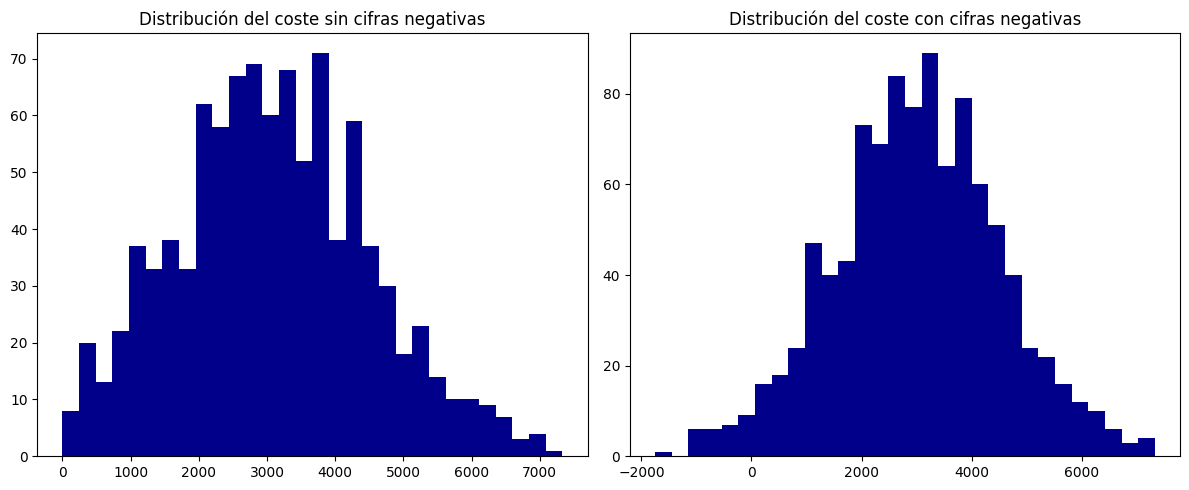

In [58]:
#Comparativa de distribuciones de la variable "coste" con y sin contar con los negativos con histogramas en subplot

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histograma sin negativos
axes[0].hist(df_sin_negativos["coste"], bins=30, color="darkblue")
axes[0].set_title("Distribución del coste sin cifras negativas")


# Histograma con negativos
axes[1].hist(df_unicos["coste"], bins=30, color="darkblue")
axes[1].set_title("Distribución del coste con cifras negativas")


plt.tight_layout()

plt.show()

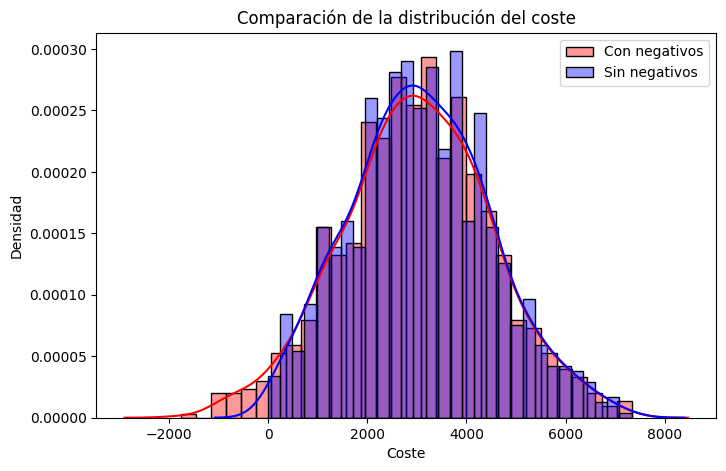

In [59]:
#Comparativa de distribuciones de probabilidad con estimaciones de densidad para ver el comportamiento de la variable "coste" con y sin contar con los negativos
plt.figure(figsize=(8,5))

# Con negativos
sns.histplot(df_unicos["coste"], bins=30, stat="density",
             color="red", alpha=0.4, label="Con negativos")

# Sin negativos
sns.histplot(df_sin_negativos["coste"], bins=30, stat="density",
             color="blue", alpha=0.4, label="Sin negativos")

# KDEs
sns.kdeplot(df_unicos["coste"], color="red")
sns.kdeplot(df_sin_negativos["coste"], color="blue")

plt.xlabel("Coste")
plt.ylabel("Densidad")
plt.title("Comparación de la distribución del coste")
plt.legend()

plt.show()

##Propuesta de solución al error de costes negativos

**Conclusiones:** Nos encontramos ante dos distribuciones normales,muy parecidas, por lo que al compararlas podemos pensar que el eliminar los datos negativos no influirá apenas en la muestra. Tras el análisis anterior la opción de eliminarlos queda descartada pues para algunos artistas significaría eliminar la mitad de sus canciones (50%), lo que es un porcentaje relevante.

Al discutir sobre las diferentes soluciones a este error, quedamos de acuerdo en sumar a la distribución "con negativos" una constante y así desplazarla hacia la derecha de tal manera que conserve su forma pero solo contenga datos positivos. Para el cálculo de esta constante se plantea la posibilidad de sumar el valor mínimo (1755,66), pero ante la posibilidad de que este número sea un outlier, se propone usar el valor mínimo dentro del rango interquatílico, el valor Q1 (2048.37).

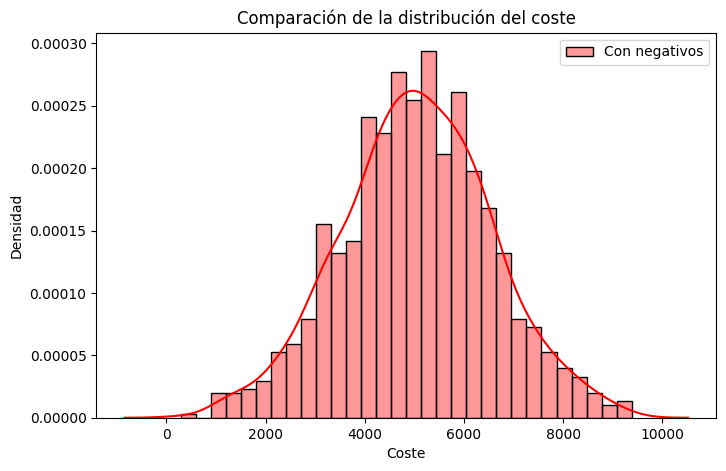

In [60]:
#Ahora el dataframe solo contendría positivos pero mantendría la misma distribución
Q1 = df_unicos["coste"].quantile(0.25)
df_correcion = df_unicos.copy() #Hacemos copia para no modificar el dataframe original "unicos"
df_correcion['coste'] = df_correcion['coste'] + Q1

plt.figure(figsize=(8,5))

sns.histplot(df_correcion["coste"], bins=30, stat="density",
             color="red", alpha=0.4, label="Con negativos")


# KDEs
sns.kdeplot(df_correcion["coste"], color="red")


plt.xlabel("Coste")
plt.ylabel("Densidad")
plt.title("Comparación de la distribución del coste")
plt.legend()

plt.show()

plt.show()

##Otros errores, reglas de negocio

###Primera regla: una canción pop no puede superar los 5000 en coste


In [61]:
#Según regla del negocio los derechos de una canción pop no pueden superar los 5000

df_pop = df_unicos[df_unicos["genero"] == "pop"]

df_pop_mayor_5000 = df_unicos[(df_unicos["genero"] == "pop") &(df_unicos["coste"] > 5000)]

porcentaje_pop_mayor_5000= len(df_pop_mayor_5000)/len(df_pop)*100

print(f"Total pop: {len(df_pop)}")
print(f"Coste mayor de 5000: {len(df_pop_mayor_5000)}")
print(f"El porcentaje de canciones pop con un coste mayor de 5000 es: {porcentaje_pop_mayor_5000:.2f}%")

Total pop: 100
Coste mayor de 5000: 8
El porcentaje de canciones pop con un coste mayor de 5000 es: 8.00%


In [62]:
df_pop_mayor_5000

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero
962,pop.00005.wav,Rihanna,Universal Music Group,6030.88,236,28,pop
990,pop.00024.wav,Maroon 5,Capitol Records,5758.81,253,21,pop
998,pop.00031.wav,Imagine Dragons,Rough Trade Records,6028.01,255,17,pop
1018,pop.00043.wav,Sam Smith,Interscope Records,6858.32,244,19,pop
1022,pop.00046.wav,Selena Gomez,XL Recordings,6399.34,259,9,pop
1035,pop.00056.wav,Zayn Malik,Island Records,5096.36,254,12,pop
1079,pop.00085.wav,Halsey,EMI Group,5032.10,257,30,pop
1089,pop.00093.wav,Ed Sheeran,Tommy Boy Entertainment,5348.40,248,8,pop


In [63]:
#Comprobar cuántas canciones pop por encima de los 5000 pertenecen a cada discográfica, por si hay algún valor que sobresalga


conteo_discograficas = df_pop_mayor_5000["discografica"].value_counts()

print(conteo_discograficas)

discografica
Universal Music Group      1
Capitol Records            1
Rough Trade Records        1
Interscope Records         1
XL Recordings              1
Island Records             1
EMI Group                  1
Tommy Boy Entertainment    1
Name: count, dtype: int64


In [64]:
#Comprobar cuántas son de cada artista y el porcentaje que representan

mayor_5000 = df_pop_mayor_5000["artistas"].value_counts()
total = df_unicos["artistas"].value_counts()

# Unimos ambas series
resultado = pd.DataFrame({
    "Total canciones": total,
    "Canciones > 5000": mayor_5000
}).fillna(0)

# Convertimos a entero la columna de canciones > 5000
resultado["Canciones > 5000"] = resultado["Canciones > 5000"].astype(int)

# Calculamos el porcentaje
resultado["Porcentaje (%)"] = (
    resultado["Canciones > 5000"] / resultado["Total canciones"] * 100
).round(2)

# Ordenamos por número de canciones > 5000
resultado = resultado.sort_values("Canciones > 5000", ascending=False)

resultado.head(8)

,Total canciones,Canciones > 5000,Porcentaje (%)
artistas,,,
Imagine Dragons,4,1,25.00
Selena Gomez,4,1,25.00
Maroon 5,2,1,50.00
Rihanna,3,1,33.33
Zayn Malik,5,1,20.00
Sam Smith,2,1,50.00
Halsey,3,1,33.33
Ed Sheeran,2,1,50.00


**Conclusión**: Aunque el porcentaje total de canciones de pop con un coste superior a 5.000 € es reducido, este límite afecta de forma desigual a los artistas. En algunos casos, como Maroon 5, Sam Smith o Ed Sheeran, el 50 % de sus canciones supera este importe, por lo que eliminarlas supondría perder el 50% de información de estos artistas.

###Segunda regla: Un mismo disco no puede superar los 50.000 en coste

In [66]:
# Según regla del negocio los derechos de las canciones de un mismo disco no pueden sobrepasar los 50000€

df_cancion = pd.read_csv(DATA_PROCESSED / "cancion.csv")
df_disco_coste = df_final_artistas_3.merge(df_cancion)

df_disco_coste


,cancion,artistas,discografica,coste,id_artista,id_discografica,genero,id_cancion,duracion,id_genero,id_disco,id_autor
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01,1,1,blues,1,00:02:18,1,1,1
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85,2,2,blues,2,00:02:22,1,2,2
2,blues.00001.wav,Buddy Guy,Epic Records,4178.85,3,2,blues,2,00:02:22,1,2,2
3,blues.00002.wav,Muddy Waters,Merge Records,3226.40,4,3,blues,3,00:01:36,1,3,4
4,blues.00002.wav,Bessie Smith,Merge Records,3226.40,5,3,blues,3,00:01:36,1,3,4
...,...,...,...,...,...,...,...,...,...,...,...,...
1366,rock.00095.wav,Pearl Jam,Stax Records,3185.88,306,25,rock,996,00:01:41,10,197,306
1367,rock.00096.wav,The Clash,Sun Records,-503.65,321,1,rock,997,00:02:50,10,194,321
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297,9,rock,998,00:02:01,10,189,297
1369,rock.00098.wav,Chuck Berry,Motown,1425.79,301,20,rock,999,00:01:39,10,187,301


In [67]:
costes_por_disco = df_disco_coste.groupby('id_disco')['coste'].sum()
print(costes_por_disco)

id_disco
1      26270.52
2      49987.29
3      20212.87
4       8870.38
5       3981.62
         ...   
196     1236.08
197    20284.60
198     7129.92
199    30946.55
200     3150.12
Name: coste, Length: 200, dtype: float64


In [69]:
#Identificamos cuáles son los discos que superan los 50000 en derechos
discos_excedidos = costes_por_disco[costes_por_disco > 50000]
print(discos_excedidos)

id_disco
45     52308.08
103    50608.06
123    52958.19
Name: coste, dtype: float64


In [70]:
#Vemos a qué discográficas pertenecen
df_disco_coste[df_disco_coste['id_disco'].isin(discos_excedidos.index)][['id_disco', 'discografica']].drop_duplicates()

,id_disco,discografica
271,45,Sony Music Entertainment
280,45,Interscope Records
284,45,Arista Records
291,45,Motown
316,45,Merge Records
320,45,Island Records
339,45,RCA Records
354,45,Tommy Boy Entertainment
362,45,Virgin Records
373,45,Sub Pop Records


In [72]:
#Cada disco puede pertenecer a varias discográficas?
df_disco_coste.groupby('id_disco')['discografica'].unique().reset_index()

,id_disco,discografica
0,1,"[Sun Records, Rough Trade Records, Capitol Rec..."
1,2,"[Epic Records, Tommy Boy Entertainment, XL Rec..."
2,3,"[Merge Records, Sire Records, 4AD, Virgin Reco..."
3,4,"[Republic Records, Elektra Records]"
4,5,[Jive Records]
...,...,...
195,196,"[EMI Group, Merge Records]"
196,197,"[Interscope Records, Columbia Records, Epic Re..."
197,198,"[Merge Records, Columbia Records]"
198,199,"[Republic Records, Island Records, Sun Records..."


In [73]:
#Vemos las canciones que pertenecen a esos discos

df_filtro_canciones_excedidos=df_disco_coste[df_disco_coste['id_disco'].isin(discos_excedidos.index)][['id_disco', 'cancion', "coste"]].sort_values("coste",ascending=False)
df_filtro_canciones_excedidos

,id_disco,cancion,coste
678,103,jazz.00004.wav,5608.37
316,45,country.00041.wav,4850.48
751,103,jazz.00057.wav,4762.11
752,103,jazz.00057.wav,4762.11
753,103,jazz.00057.wav,4762.11
380,45,country.00089.wav,4730.09
362,45,country.00076.wav,4611.24
363,45,country.00076.wav,4611.24
920,123,metal.00074.wav,4345.91
919,123,metal.00074.wav,4345.91


In [74]:
#Calculamos el porcentaje de coste que representa cada cancion en el total del disco
totales_disco = df_filtro_canciones_excedidos.groupby('id_disco')['coste'].transform('sum')
df_filtro_canciones_excedidos['porcentaje_disco'] = (df_filtro_canciones_excedidos['coste'] / totales_disco) * 100
df_filtro_canciones_excedidos.sort_values(['id_disco', 'coste'],ascending=[True, False])

,id_disco,cancion,coste,porcentaje_disco
316,45,country.00041.wav,4850.48,9.272908
380,45,country.00089.wav,4730.09,9.042752
362,45,country.00076.wav,4611.24,8.815541
363,45,country.00076.wav,4611.24,8.815541
271,45,country.00004.wav,4340.41,8.297781
374,45,country.00085.wav,4078.53,7.797132
373,45,country.00084.wav,3943.06,7.538147
354,45,country.00071.wav,3103.27,5.932678
281,45,country.00013.wav,2717.20,5.194609
280,45,country.00013.wav,2717.20,5.194609


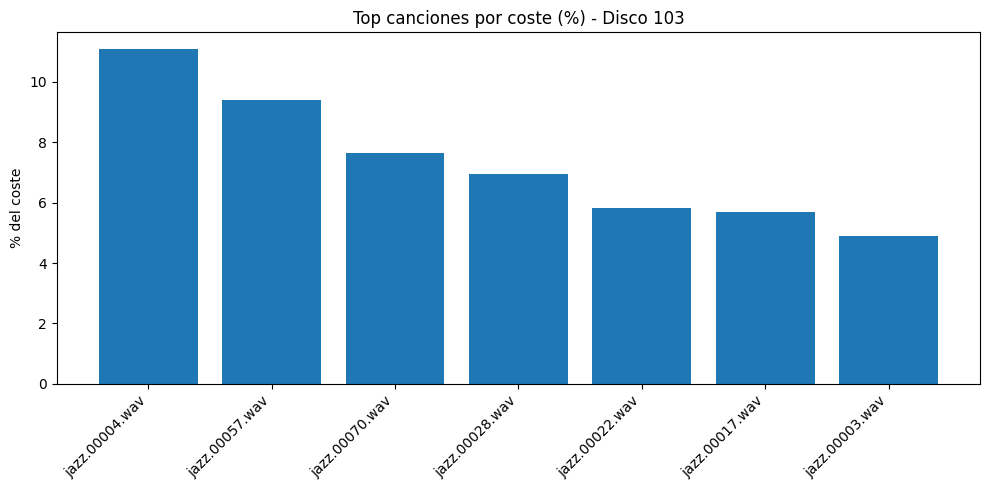

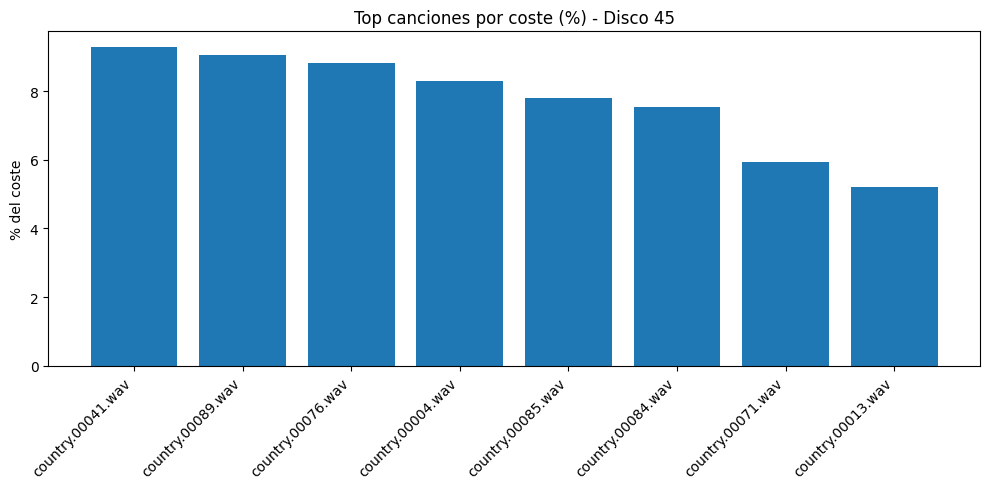

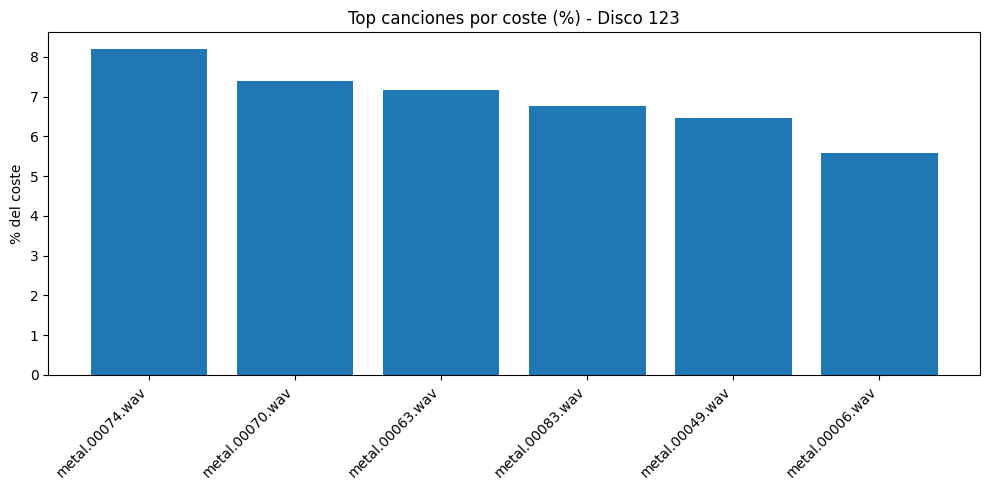

In [75]:
for disco in df_filtro_canciones_excedidos['id_disco'].unique():

    df_plot = df_filtro_canciones_excedidos[
        df_filtro_canciones_excedidos['id_disco'] == disco
    ].sort_values('porcentaje_disco', ascending=False).head(10)

    plt.figure(figsize=(10, 5))
    plt.bar(df_plot['cancion'], df_plot['porcentaje_disco'])

    plt.title(f'Top canciones por coste (%) - Disco {disco}')
    plt.ylabel('% del coste')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

**Conclusión**: El análisis muestra que el coste de los discos no está concentrado en una única canción dominante, sino que está bastante repartido entre varias pistas, lo que sugiere que los discos con costes superiores a 50.000 € no se explican por un único outlier, sino por la acumulación de varias canciones con contribuciones similares.

In [76]:
#¿Qué proporción de los discos de cada género se eliminaría? Identificamos el género de estos discos
df_discos_genero = ( df_disco_coste[df_disco_coste['id_disco'].isin(discos_excedidos.index)] [['id_disco', 'genero']] .drop_duplicates() )
df_discos_genero

,id_disco,genero
271,45,country
675,103,jazz
817,123,metal


In [84]:
#Vemos que porcentaje representa los discos excedidos por género en el total de discos
# Total de discos por género en todo el dataset
total_discos_genero = (
    df_disco_coste[['id_disco', 'genero']]
    .drop_duplicates()
    .groupby('genero')['id_disco']
    .count()
)
# Discos excedidos por género
discos_excedidos_genero = (
    df_discos_genero
    .groupby('genero')['id_disco']
    .count()
)
# Comparación
comparacion = pd.concat(
    [total_discos_genero, discos_excedidos_genero],
    axis=1,
    keys=['total_discos', 'discos_excedidos']
).fillna(0)

comparacion['porcentaje'] = (
    comparacion['discos_excedidos']
    / comparacion['total_discos'] * 100
).round(2)

comparacion.reset_index().sort_values(by="discos_excedidos", ascending=False)


,genero,total_discos,discos_excedidos,porcentaje
5,jazz,20,1.0,5.0
2,country,20,1.0,5.0
6,metal,20,1.0,5.0
0,blues,20,0.0,0.0
1,classical,20,0.0,0.0
3,disco,20,0.0,0.0
4,hiphop,20,0.0,0.0
7,pop,20,0.0,0.0
8,reggae,20,0.0,0.0
9,rock,20,0.0,0.0


In [85]:
#¿Qué proporción de canciones por género se eliminaría con esta regla de negocio?
# Total de canciones por género
total_canciones_genero = (
    df_disco_coste
    .groupby('genero')['cancion']
    .count()
    .rename('total_canciones')
)

# Canciones de los discos excedidos por género
canciones_excedidas_genero = (
    df_disco_coste[df_disco_coste['id_disco'].isin(discos_excedidos.index)]
    .groupby('genero')['cancion']
    .count()
    .rename('canciones_excedidas')
)

# Comparación
comparacion_canciones = pd.concat(
    [total_canciones_genero, canciones_excedidas_genero],
    axis=1
).fillna(0)

comparacion_canciones['porcentaje'] = (
    comparacion_canciones['canciones_excedidas']
    / comparacion_canciones['total_canciones'] * 100
).round(2)

comparacion_canciones.reset_index().sort_values(by="canciones_excedidas", ascending=False)

,genero,total_canciones,canciones_excedidas,porcentaje
6,metal,143,18.0,12.59
2,country,127,16.0,12.60
5,jazz,142,16.0,11.27
0,blues,143,0.0,0.00
1,classical,122,0.0,0.00
3,disco,131,0.0,0.00
4,hiphop,148,0.0,0.00
7,pop,145,0.0,0.00
8,reggae,136,0.0,0.00
9,rock,134,0.0,0.00


**Conclusión**: Se identificaron tres discos con un coste superior a 50.000 €. Aunque constituyen únicamente el 5 % de los discos de sus respectivos géneros, en dos de ellos representan el 12,6 % de las canciones de su género, por lo que su eliminación podría afectar a la representatividad del género en cuestión.

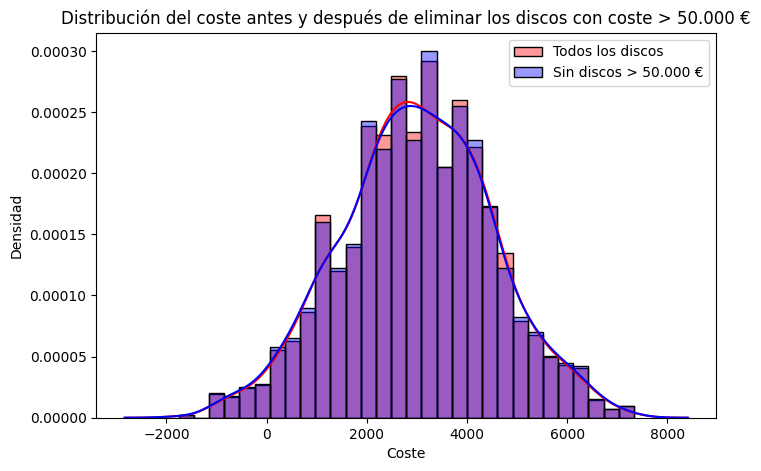

In [86]:
#Comparamos el coste eliminando las canciones de los discos excedidos y sin eliminar estas canciones
plt.figure(figsize=(8,5))

# Dataset completo
sns.histplot(
    df_disco_coste["coste"],
    bins=30,
    stat="density",
    color="red",
    alpha=0.4,
    label="Todos los discos"
)

# Dataset sin los discos con coste > 50.000 €
sns.histplot(
    df_disco_coste[
        ~df_disco_coste["id_disco"].isin(discos_excedidos.index)
    ]["coste"],
    bins=30,
    stat="density",
    color="blue",
    alpha=0.4,
    label="Sin discos > 50.000 €"
)

# Curvas KDE
sns.kdeplot(
    df_disco_coste["coste"],
    color="red"
)

sns.kdeplot(
    df_disco_coste[
        ~df_disco_coste["id_disco"].isin(discos_excedidos.index)
    ]["coste"],
    color="blue"
)

plt.xlabel("Coste")
plt.ylabel("Densidad")
plt.title("Distribución del coste antes y después de eliminar los discos con coste > 50.000 €")
plt.legend()

plt.show()

In [87]:
comparacion_coste_cancion = pd.DataFrame({
    "Con discos excedidos": df_disco_coste['coste'].describe(),
    "Sin discos excedidos": df_disco_coste[
        ~df_disco_coste['id_disco'].isin(discos_excedidos.index)
    ]['coste'].describe()
})

comparacion_coste_cancion

,Con discos excedidos,Sin discos excedidos
count,1371.000000,1321.000000
mean,3000.635791,2996.212975
std,1504.816144,1516.652183
min,-1755.660000,-1755.660000
25%,2048.975000,2031.370000
50%,2994.090000,3023.110000
75%,4014.090000,4014.090000
max,7331.900000,7331.900000


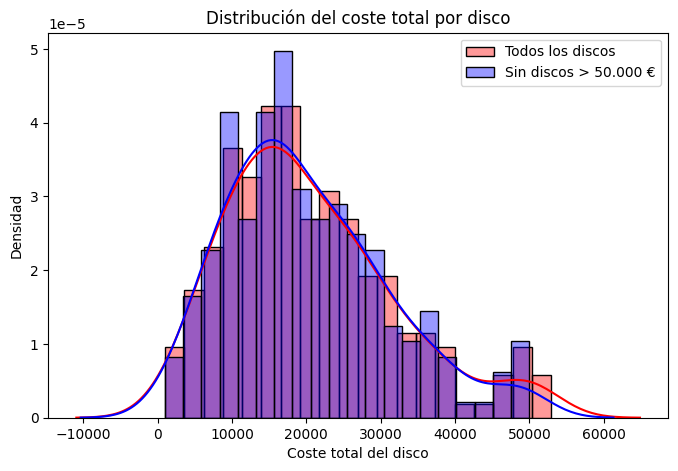

In [88]:
#Comparamos el coste por disco eliminando y sin eliminar los discos excedidos
costes_sin_excedidos = costes_por_disco[costes_por_disco <= 50000]
plt.figure(figsize=(8,5))

# Todos los discos
sns.histplot(
    costes_por_disco,
    bins=20,
    stat="density",
    color="red",
    alpha=0.4,
    label="Todos los discos"
)

# Sin discos excedidos
sns.histplot(
    costes_sin_excedidos,
    bins=20,
    stat="density",
    color="blue",
    alpha=0.4,
    label="Sin discos > 50.000 €"
)

# Curvas KDE
sns.kdeplot(costes_por_disco, color="red")
sns.kdeplot(costes_sin_excedidos, color="blue")

plt.xlabel("Coste total del disco")
plt.ylabel("Densidad")
plt.title("Distribución del coste total por disco")
plt.legend()

plt.show()

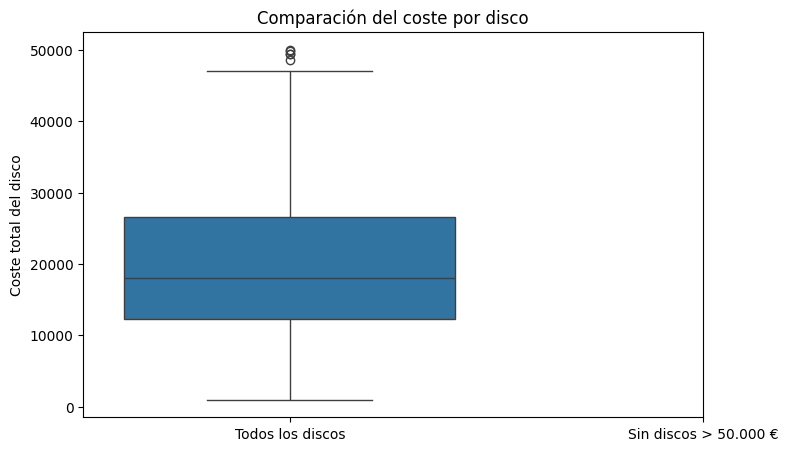

In [89]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=[costes_por_disco, costes_sin_excedidos]
)

plt.xticks(
    [0,1],
    ["Todos los discos", "Sin discos > 50.000 €"]
)

plt.ylabel("Coste total del disco")
plt.title("Comparación del coste por disco")

plt.show()

In [90]:
comparacion_coste_disco = pd.DataFrame({
    "Todos": costes_por_disco.describe(),
    "Sin excedidos": costes_sin_excedidos.describe()
})

comparacion_coste_disco

,Todos,Sin excedidos
count,200.000000,197.000000
mean,20569.358350,20091.357056
std,11445.888306,10848.432928
min,972.410000,972.410000
25%,12338.457500,12334.310000
50%,18127.480000,17985.290000
75%,26879.122500,26588.160000
max,52958.190000,49987.290000


**Conclusión**: Con el fin de evaluar el impacto de los tres discos cuyo coste supera los 50.000 €, se compararon los estadísticos descriptivos del coste antes y después de su eliminación. A nivel de canción, la media pasó de 3.000,64 € a 2.996,21 €, lo que supone una variación de únicamente el 0,15 %. A nivel de disco, la media descendió de 20.569,36 € a 20.091,36 €, una reducción del 2,32 %. Estos resultados, junto con la similitud observada en la distribución de los costes, indican que dichos discos no ejercen una influencia significativa sobre el comportamiento general del dataset. Por tanto, simplemente tener en cuenta que el eliminarlos podría reducir la representatividad de algunos géneros.

###Tercera regla: Un artista no puede publicar más de 5 canciones en un mismo día

In [92]:
# Según regla del negocio un artista no puede publicar mas de 5 canciones en un mismo día

# Añadimos columna id_cancion a la tabla de artistas
df_artista_cancion = pd.merge(df_final_artistas_3, df_cancion[['id_cancion','cancion']], on=['cancion'], how='left')

# Añadimos columna fecha de publicacion
df_fecha_publicacion = pd.read_csv(DATA_PROCESSED / "fecha_publicacion.csv")
df_artista_fecha = pd.merge(df_artista_cancion, df_fecha_publicacion, on=['id_cancion'], how='left')
df_artista_fecha


,cancion,artistas,discografica,coste,id_artista,id_discografica,genero,id_cancion,fecha_publicacion
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01,1,1,blues,1,NaN
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85,2,2,blues,2,2023-07-31
2,blues.00001.wav,Buddy Guy,Epic Records,4178.85,3,2,blues,2,2023-07-31
3,blues.00002.wav,Muddy Waters,Merge Records,3226.40,4,3,blues,3,2023-06-14
4,blues.00002.wav,Bessie Smith,Merge Records,3226.40,5,3,blues,3,2023-06-14
...,...,...,...,...,...,...,...,...,...
1366,rock.00095.wav,Pearl Jam,Stax Records,3185.88,306,25,rock,996,2022-10-20
1367,rock.00096.wav,The Clash,Sun Records,-503.65,321,1,rock,997,2021-09-24
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297,9,rock,998,2022-08-11
1369,rock.00098.wav,Chuck Berry,Motown,1425.79,301,20,rock,999,2022-02-27


In [93]:
#Agrupamos por artista y fecha
num_cancion_artista = df_artista_fecha.groupby(['artistas','fecha_publicacion']).agg(num_canciones=('id_cancion', 'count')).reset_index()
num_cancion_artista

,artistas,fecha_publicacion,num_canciones
0,2Pac,2021-11-14,1
1,2Pac,2022-02-26,1
2,2Pac,2023-07-24,1
3,2Pac,2023-08-26,1
4,2Pac,2023-11-15,1
...,...,...,...
1136,Zayn Malik,2023-12-17,1
1137,Ziggy Marley,2021-04-19,1
1138,Ziggy Marley,2021-05-29,1
1139,Ziggy Marley,2022-10-18,1


In [94]:
num_cancion_artista[num_cancion_artista['num_canciones']>5]

,artistas,fecha_publicacion,num_canciones


In [95]:
num_cancion_artista["num_canciones"].max()

1

In [96]:
#Comprobemos con un segundo metodo para asegurarnos que no hay artitas con mas 5 canciones un día
num_fecha_cancion = (df_artista_fecha.groupby('fecha_publicacion').agg(num_canciones=('id_cancion', 'nunique')).reset_index())
num_fecha_cancion

,fecha_publicacion,num_canciones
0,2021-01-01,3
1,2021-01-02,1
2,2021-01-04,2
3,2021-01-05,2
4,2021-01-06,1
...,...,...
567,2023-12-24,1
568,2023-12-27,1
569,2023-12-28,1
570,2023-12-29,1


In [97]:
max_canciones = num_fecha_cancion["num_canciones"].max()

num_fecha_cancion[num_fecha_cancion["num_canciones"] == max_canciones]

,fecha_publicacion,num_canciones
318,2022-08-11,5
325,2022-08-23,5


In [98]:
df_artista_fecha[df_artista_fecha["fecha_publicacion"] == "2022-08-11"]

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero,id_cancion,fecha_publicacion
455,disco.00049.wav,Village People,4AD,1455.99,105,22,disco,350,2022-08-11
727,jazz.00039.wav,Duke Ellington,EMI Group,2902.21,169,30,jazz,540,2022-08-11
794,jazz.00084.wav,Count Basie,EMI Group,5623.81,195,30,jazz,585,2022-08-11
1204,reggae.00077.wav,Sizzla,Verve Records,1685.03,264,23,reggae,878,2022-08-11
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297,9,rock,998,2022-08-11


In [99]:
df_artista_fecha[df_artista_fecha["fecha_publicacion"] == "2022-08-23"]

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero,id_cancion,fecha_publicacion
396,disco.00002.wav,Patrick Hernandez,Sun Records,2198.35,104,1,disco,303,2022-08-23
814,metal.00001.wav,Axl Rose,Virgin Records,3350.28,203,26,metal,602,2022-08-23
896,metal.00058.wav,Joey DeMaio,4AD,382.34,211,22,metal,659,2022-08-23
941,metal.00089.wav,Floor Jansen,Capitol Records,4014.09,202,21,metal,690,2022-08-23
942,metal.00089.wav,Mikael Akerfeldt,Capitol Records,4014.09,217,21,metal,690,2022-08-23
943,metal.00089.wav,Max Cavalera,Capitol Records,4014.09,220,21,metal,690,2022-08-23
1065,pop.00075.wav,Charlie Puth,RCA Records,2637.05,256,11,pop,776,2022-08-23


**Conclusión**: Se ha verificado esta regla de negocio mediante dos comprobaciones. En primer lugar, se contabilizó el número de canciones publicadas por cada artista en cada fecha de publicación, observándose que ningún artista supera una canción en un mismo día. En segundo lugar, se analizó el número total de canciones publicadas por fecha, comprobando que el máximo de publicaciones en un mismo día es de cinco, repartidas entre distintos artistas. Por tanto, se concluye que la regla de negocio se cumple, ya que no existe ningún artista que haya publicado más de cinco canciones en el mismo día.

#EDA

## Análisis de outliers

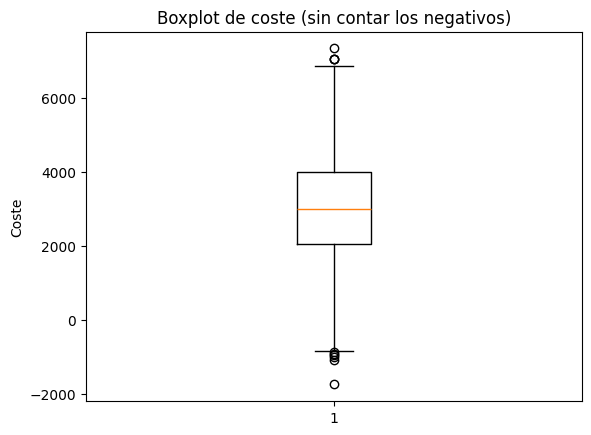

In [100]:
plt.figure()
plt.boxplot(df_unicos["coste"])
plt.title("Boxplot de coste (sin contar los negativos)")
plt.ylabel("Coste")
plt.show()

In [101]:
#Buscar los outliers del dataframe
Q1 = df_unicos["coste"].quantile(0.25)
Q3 = df_unicos["coste"].quantile(0.75)
IQR = Q3 - Q1

outliers = df_unicos[(df_unicos["coste"] > (Q3 + 1.5 * IQR)) | (df_unicos["coste"] < (Q1 - 1.5 * IQR))]

display(outliers.sort_values(by="coste", ascending=False))

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero
906,metal.00065.wav,Joey DeMaio,Stax Records,7331.90,211,25,metal
242,classical.00078.wav,Johannes Brahms,Universal Music Group,7050.61,37,28,classical
340,country.00059.wav,Keith Urban,4AD,7049.92,79,22,country
196,classical.00044.wav,Camille Saint-Saëns,Atlantic Records,7037.70,58,10,classical
341,country.00060.wav,Martina McBride,Elektra Records,-884.22,73,18,country
533,hiphop.00007.wav,Beyoncé,Merge Records,-918.44,134,3,hiphop
260,classical.00095.wav,George Frideric Handel,Merge Records,-946.54,65,3,classical
818,metal.00004.wav,Ozzy Osbourne,Polydor Records,-1008.08,207,6,metal
540,hiphop.00012.wav,Biggie Smalls,Stax Records,-1099.03,148,25,hiphop
984,pop.00020.wav,Adele,Def Jam Recordings,-1755.66,249,16,pop


In [102]:
outliers_superiores = df_unicos[df_unicos["coste"] > Q3 + 1.5 * IQR]
outliers_inferiores = df_unicos[df_unicos["coste"] < Q1 - 1.5 * IQR]

print(f"Outliers superiores: {len(outliers_superiores)}")
print(f"Outliers inferiores: {len(outliers_inferiores)}")

Outliers superiores: 4
Outliers inferiores: 6


In [103]:
display(outliers_superiores.sort_values("coste", ascending=False))
display(outliers_inferiores.sort_values("coste", ascending=True))

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero
906,metal.00065.wav,Joey DeMaio,Stax Records,7331.90,211,25,metal
242,classical.00078.wav,Johannes Brahms,Universal Music Group,7050.61,37,28,classical
340,country.00059.wav,Keith Urban,4AD,7049.92,79,22,country
196,classical.00044.wav,Camille Saint-Saëns,Atlantic Records,7037.70,58,10,classical


,cancion,artistas,discografica,coste,id_artista,id_discografica,genero
984,pop.00020.wav,Adele,Def Jam Recordings,-1755.66,249,16,pop
540,hiphop.00012.wav,Biggie Smalls,Stax Records,-1099.03,148,25,hiphop
818,metal.00004.wav,Ozzy Osbourne,Polydor Records,-1008.08,207,6,metal
260,classical.00095.wav,George Frideric Handel,Merge Records,-946.54,65,3,classical
533,hiphop.00007.wav,Beyoncé,Merge Records,-918.44,134,3,hiphop
341,country.00060.wav,Martina McBride,Elektra Records,-884.22,73,18,country


In [104]:
total_outliers = len(outliers)
total_registros = len(df_unicos)

porcentaje_outliers = total_outliers / total_registros * 100

print(f"Número de outliers: {total_outliers}")
print(f"Representan el {porcentaje_outliers:.2f}% del total de registros")

Número de outliers: 10
Representan el 1.00% del total de registros


In [105]:
display(outliers["coste"].describe())

,coste
count,10.000000
mean,2185.816000
std,4252.427878
min,-1755.660000
25%,-992.695000
50%,-901.330000
75%,7046.865000
max,7331.900000


In [106]:
#Análisis de outliers por discográfica
total_discografica = df_unicos.groupby("discografica").size().rename("total_discografica")

outliers_discografica = outliers.groupby("discografica").size().rename("outliers")

analisis_discografica = (pd.concat([total_discografica, outliers_discografica], axis=1).fillna(0))

analisis_discografica["outliers"] = analisis_discografica["outliers"].astype(int)

analisis_discografica["porcentaje_outliers"] = (analisis_discografica["outliers"] /analisis_discografica["total_discografica"] * 100).round(2)

display(analisis_discografica.sort_values("porcentaje_outliers",ascending=False))

,total_discografica,outliers,porcentaje_outliers
discografica,,,
Stax Records,31,2,6.45
Def Jam Recordings,25,1,4.00
Universal Music Group,25,1,4.00
Elektra Records,26,1,3.85
Atlantic Records,30,1,3.33
Polydor Records,35,1,2.86
Merge Records,80,2,2.50
4AD,41,1,2.44
EMI Group,34,0,0.00


In [107]:
# Analisis de outliers por género

total_genero = df_unicos.groupby("genero").size().rename("total_genero")

outliers_genero = outliers.groupby("genero").size().rename("outliers")

analisis_genero = (pd.concat([total_genero, outliers_genero], axis=1).fillna(0))

analisis_genero["outliers"] = analisis_genero["outliers"].astype(int)

analisis_genero["porcentaje_outliers"] = (analisis_genero["outliers"] /analisis_genero["total_genero"] * 100).round(2)

display(analisis_genero.sort_values("porcentaje_outliers", ascending=False))


,total_genero,outliers,porcentaje_outliers
genero,,,
classical,100,3,3.0
country,100,2,2.0
metal,100,2,2.0
hiphop,100,2,2.0
pop,100,1,1.0
blues,100,0,0.0
jazz,100,0,0.0
disco,100,0,0.0
reggae,100,0,0.0


**Conclusiones:** Los outliers representan únicamente el  1% del total de registros, por lo que son casos poco frecuentes.

El género classical presenta el mayor porcentaje de outliers (3 %).

Aunque la discográfica Merge Records y la discográfica Stax Records tienen el mayor número absoluto de outliers, solo la discográfica Stax Records es la que presenta una mayor proporción respecto al total de sus canciones (6.45%).
Esto puede sugerir que determinadas discográficas o géneros concentran los pagos más elevados y se analizarán más adelante.

##Comparativa con outliers vs sin outliers

In [108]:
df_sin_outliers = df_unicos[~df_unicos.index.isin(outliers.index)]

print("Media con outliers:", df_unicos["coste"].mean())
print("Media sin outliers:", df_sin_outliers["coste"].mean())

Media con outliers: 2998.77321
Media sin outliers: 3006.9848989898987


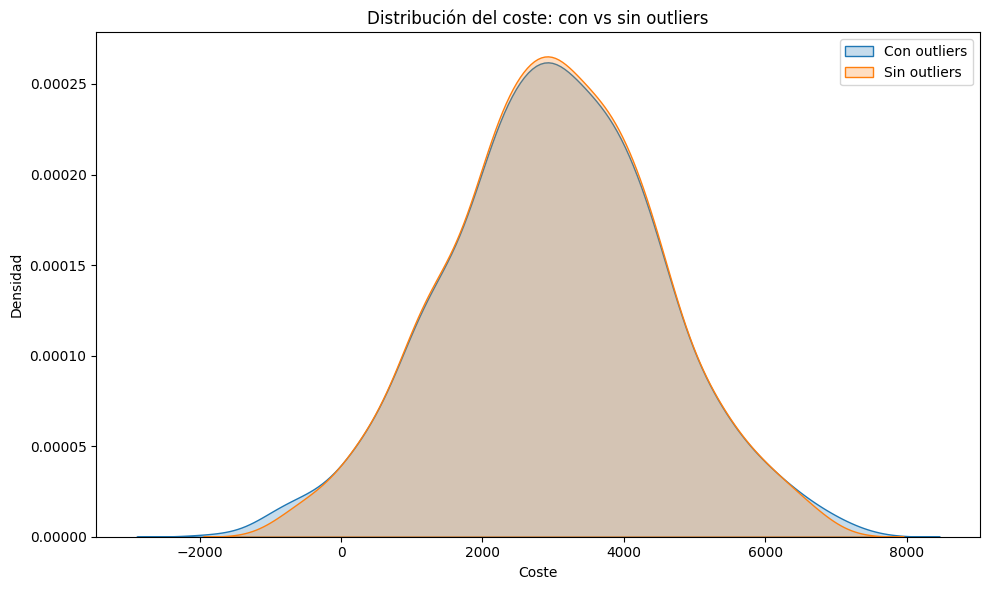

In [109]:
plt.figure(figsize=(10,6))

# Distribución con outliers
sns.kdeplot(
    data=df_unicos,
    x="coste",
    fill=True,
    label="Con outliers"
)

# Distribución sin outliers
sns.kdeplot(
    data=df_sin_outliers,
    x="coste",
    fill=True,
    label="Sin outliers"
)

plt.title("Distribución del coste: con vs sin outliers")
plt.xlabel("Coste")
plt.ylabel("Densidad")
plt.legend()

plt.tight_layout()
plt.show()

**Conclusión:** Se identificaron 4 outliers superiores y 6 outliers inferiores según el criterio del rango intercuartílico (IQR). Aunque la diferencia entre ambos grupos es pequeña, el hecho de que la media aumente ligeramente al eliminar los valores atípicos (pasando de 2998,77 a 3006,98) sugiere que, en conjunto, los outliers inferiores ejercen una influencia ligeramente mayor sobre el coste medio que los superiores.

Asimismo, la comparación de las distribuciones del coste con y sin outliers muestra que ambas presentan una forma muy similar, sin diferencias significativas en su densidad. Esto indica que, si bien existen observaciones clasificadas como valores atípicos según el criterio del IQR, su impacto sobre la distribución global de la variable y sobre el valor medio del coste es muy reducido. Por tanto, puede concluirse que estos casos aislados no alteran de forma significativa las conclusiones obtenidas en el análisis descriptivo.



##Análisis de coste por discográfica y género

In [110]:
#Sacamos las medias de coste de los géneros y el total de canciones de cada género para ver si hay algún género que se pague mucho más

media_genero = ( df_unicos.groupby("genero").agg( media_coste=("coste", "mean"),total_canciones=("coste", "size")).reset_index())
media_total=df_unicos["coste"].mean()


print(f"La media total de coste es {media_total:.2f}")
print("\n")

#Y también la media por canción
media_genero["media_coste_cancion"] = (media_genero["media_coste"] / media_genero["total_canciones"])
display(media_genero.sort_values(by="media_coste_cancion", ascending=False))



La media total de coste es 2998.77




,genero,media_coste,total_canciones,media_coste_cancion
4,hiphop,3174.7744,100,31.747744
0,blues,3091.0005,100,30.910005
1,classical,3026.0259,100,30.260259
6,metal,3007.7615,100,30.077615
3,disco,2996.6431,100,29.966431
5,jazz,2981.5998,100,29.815998
9,rock,2934.6852,100,29.346852
8,reggae,2934.1592,100,29.341592
7,pop,2929.4662,100,29.294662
2,country,2911.6163,100,29.116163


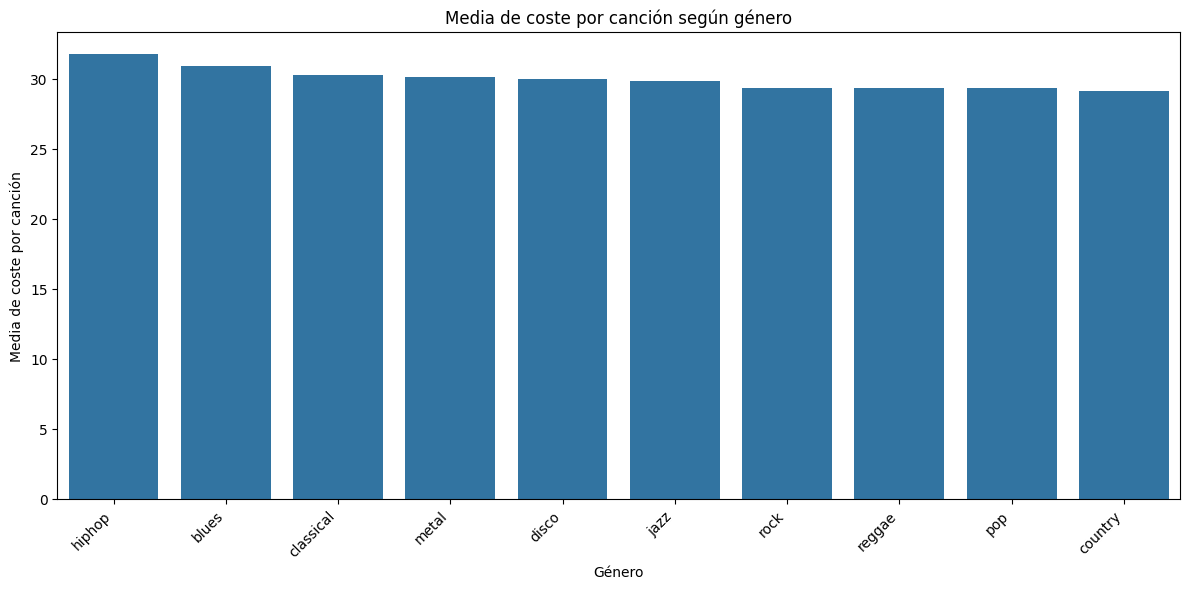

In [111]:
df_plot = media_genero.sort_values(by="media_coste_cancion", ascending=False)

plt.figure(figsize=(12,6))
sns.barplot(data=df_plot, x="genero", y="media_coste_cancion")

plt.title("Media de coste por canción según género")
plt.xlabel("Género")
plt.ylabel("Media de coste por canción")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

**Conclusión**: El análisis de la media del coste por canción según el género muestra una distribución muy homogénea entre todos los géneros musicales. Aunque el hip-hop presenta el mayor coste medio por canción y el country el menor, las diferencias observadas son muy reducidas.

In [112]:
#Saco las medias de coste por discografica sin negativos para ver si hay alguna discografica a la que se pague mucho más

media_discografica = ( df_unicos.groupby("discografica").agg( media_coste=("coste", "mean")).reset_index().round(2))
media_total_discografica=df_unicos["coste"].mean()

print(f"La media total de coste sin contar los negativos es {media_total_discografica:.2f}")
print("\n")

display(media_discografica.sort_values(by="media_coste", ascending=False))


La media total de coste sin contar los negativos es 2998.77




,discografica,media_coste
27,Verve Records,3510.21
2,Atlantic Records,3508.50
30,Wind-Up Records,3491.13
4,Capitol Records,3468.98
26,Universal Music Group,3347.32
19,Rough Trade Records,3334.67
3,BMG Rights Management,3312.86
25,Tommy Boy Entertainment,3296.96
23,Sub Pop Records,3223.94
1,Arista Records,3206.55


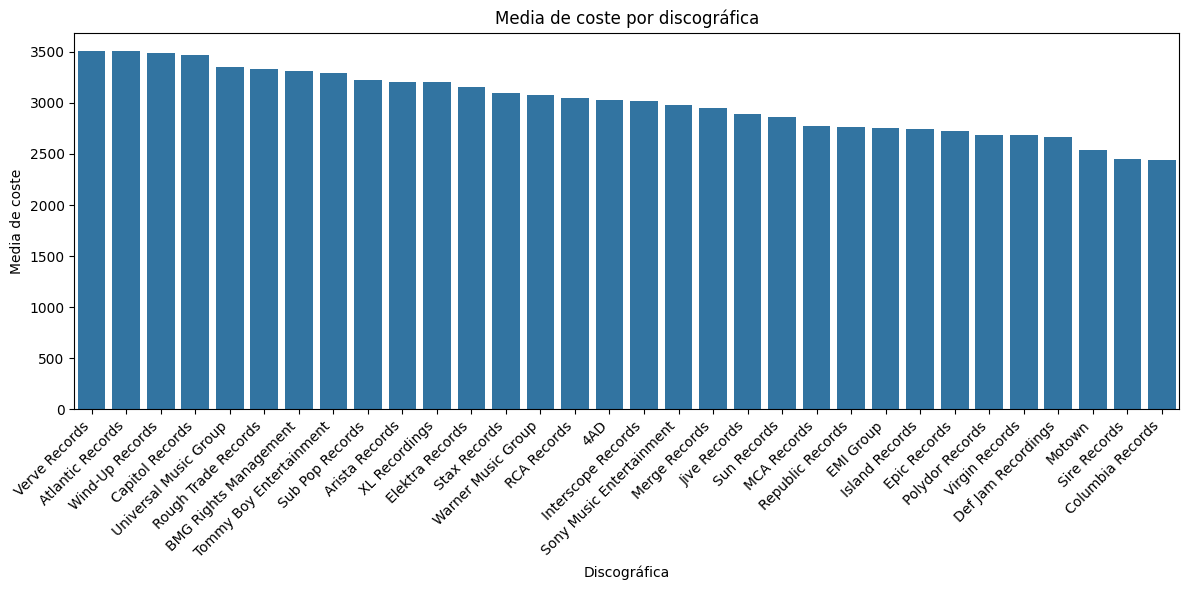

In [113]:
df_plot = media_discografica.sort_values(by="media_coste", ascending=False)

plt.figure(figsize=(12,6))
sns.barplot(data=df_plot, x="discografica", y="media_coste")

plt.title("Media de coste por discográfica")
plt.xlabel("Discográfica")
plt.ylabel("Media de coste")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

**Conclusión**: El análisis de la media del coste por canción según la discográfica muestra una mayor variabilidad que la observada entre géneros. En concreto, Verve Records presenta el mayor coste medio por canción (3.510,21 €), mientras que Columbia Records registra el menor (2.439,06 €). La diferencia entre ambas supera los 1.000 €, lo que indica que la discográfica parece tener una mayor influencia sobre el coste medio de las canciones que el género musical. Estas diferencias podrían deberse a las políticas de inversión o el tipo de producciones asociadas a cada discográfica, pero con la información disponible no es posible establecer una relación causal.

In [114]:
#Saco las discograficas superiores a la media y cuanto se diferencian de la media

media_discografica["diferencia_media"] = (media_discografica["media_coste"] - media_total_discografica).round(2)

discograficas_superiores = media_discografica[media_discografica["media_coste"] > media_total_discografica]
display(discograficas_superiores.sort_values(by="diferencia_media", ascending=False))
total_discograficas = df_unicos["discografica"].nunique()

porcentaje_discografica_sup = (len(discograficas_superiores) / total_discograficas * 100)
print("\n")
print(f"Total de discográficas por encima de la media: {len(discograficas_superiores)}")
print(f"Porcentaje de discográficas por encima de la media: {porcentaje_discografica_sup:.2f}")

,discografica,media_coste,diferencia_media
27,Verve Records,3510.21,511.44
2,Atlantic Records,3508.50,509.73
30,Wind-Up Records,3491.13,492.36
4,Capitol Records,3468.98,470.21
26,Universal Music Group,3347.32,348.55
19,Rough Trade Records,3334.67,335.90
3,BMG Rights Management,3312.86,314.09
25,Tommy Boy Entertainment,3296.96,298.19
23,Sub Pop Records,3223.94,225.17
1,Arista Records,3206.55,207.78




Total de discográficas por encima de la media: 17
Porcentaje de discográficas por encima de la media: 53.12


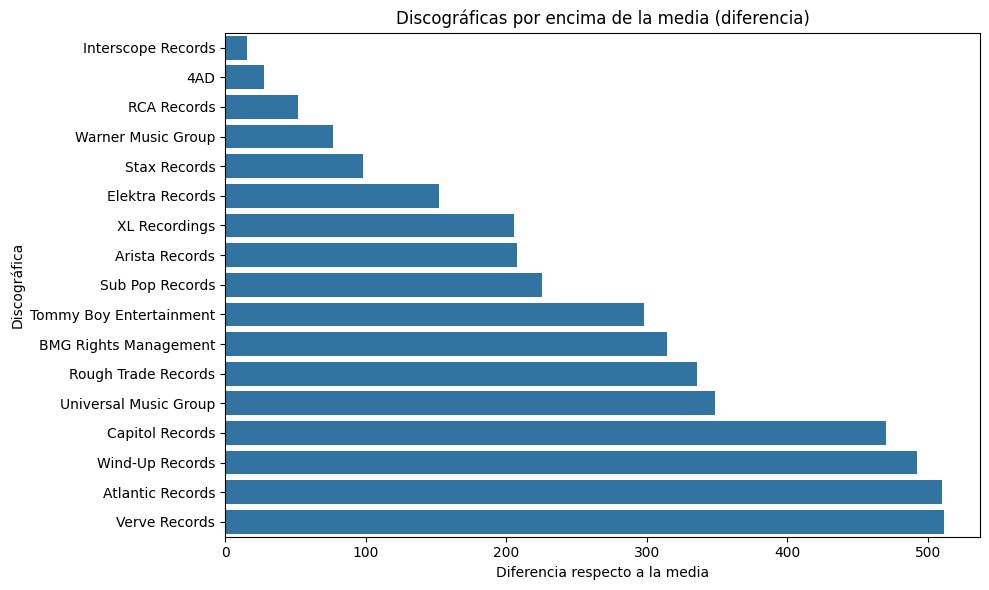

In [115]:
df_plot = discograficas_superiores.sort_values(by="diferencia_media", ascending=True)

plt.figure(figsize=(10,6))
sns.barplot(data=df_plot, x="diferencia_media", y="discografica")

plt.title("Discográficas por encima de la media (diferencia)")
plt.xlabel("Diferencia respecto a la media")
plt.ylabel("Discográfica")

plt.tight_layout()
plt.show()

**Conclusión**: A diferencia del análisis por género, donde las medias eran muy similares entre sí, el análisis por discográfica revela una mayor variabilidad en el coste medio por canción. Sin embargo, esta variabilidad no se concentra en un número reducido de discográficas, sino que más de la mitad presentan valores superiores a la media global, lo que sugiere una distribución relativamente equilibrada de los costes entre ellas.

#Tratamiento para carga de datos en SQL

In [ ]:
df_final_artistas_3.to_csv(DATA_PROCESSED / "artistas.csv", index=False)
df_final_artistas_3.to_csv(DATA_PROCESSED / "artistas_ids.csv", index=False)


In [ ]:
# Añadimos las columnas de id_genero e id_cancion de la tabla cancioninfo
df_cancion2 = pd.read_csv(DATA_PROCESSED / "cancion.csv")


In [ ]:
df_final_artistas_4 = df_final_artistas_3.merge(
    df_cancion2[["cancion", "id_cancion"]],
    on="cancion",
    how="left"
).merge(
    df_cancion2[["cancion", "id_genero"]],
    on="cancion",
    how="left"
)

df_final_artistas_4

,cancion,artistas,discografica,coste,id_artista,id_discografica,genero,id_cancion,id_genero
0,blues.00000.wav,Stevie Ray Vaughan,Sun Records,744.01,1,1,blues,1,1
1,blues.00001.wav,Sonny Boy Williamson,Epic Records,4178.85,2,2,blues,2,1
2,blues.00001.wav,Buddy Guy,Epic Records,4178.85,3,2,blues,2,1
3,blues.00002.wav,Muddy Waters,Merge Records,3226.40,4,3,blues,3,1
4,blues.00002.wav,Bessie Smith,Merge Records,3226.40,5,3,blues,3,1
...,...,...,...,...,...,...,...,...,...
1366,rock.00095.wav,Pearl Jam,Stax Records,3185.88,306,25,rock,996,10
1367,rock.00096.wav,The Clash,Sun Records,-503.65,321,1,rock,997,10
1368,rock.00097.wav,Fleetwood Mac,XL Recordings,2170.05,297,9,rock,998,10
1369,rock.00098.wav,Chuck Berry,Motown,1425.79,301,20,rock,999,10


In [ ]:
df_artistas_sql=df_final_artistas_4[["id_artista", "id_cancion"]]
df_artistas_sql

,id_artista,id_cancion
0,1,1
1,2,2
2,3,2
3,4,3
4,5,3
...,...,...
1366,306,996
1367,321,997
1368,297,998
1369,301,999


In [ ]:
df_artistas_sql.to_csv(DATA_PROCESSED / "artistas_sql.csv", index=False)


In [ ]:
#Me quedo con los no duplicados porque el id_artista será una PK en SQL
df_id_artistas_sql = df_final_artistas_4[["id_artista", "artistas"]].drop_duplicates(subset=["id_artista"])
df_id_artistas_sql

,id_artista,artistas
0,1,Stevie Ray Vaughan
1,2,Sonny Boy Williamson
2,3,Buddy Guy
3,4,Muddy Waters
4,5,Bessie Smith
...,...,...
1303,322,Bruce Springsteen
1312,323,Pink Floyd
1324,324,Metallica
1334,325,The Police


In [ ]:
df_id_artistas_sql.to_csv(DATA_PROCESSED / "id_artistas_sql.csv", index=False)
